# 01 · Pub decline (Q1)
**Question:** How fast are pubs disappearing in Ireland, and where?

**Data:** `data/processed/pubs_national.csv` (2005–2025) and `pubs_county_long.csv` (26 counties; 2005 and 2019–2025), produced by `src/clean.py`.
Source: DIGI / A. Foley reports, based on the Revenue licence register. See `data/DATA_DICTIONARY.md` for known source errors and corrections.

**Sections**
1. National trend
2. Closures by period
3. Which counties lost the most?
4. Dublin vs the rest of Ireland
5. Since the pandemic (2019 → 2025)
6. Findings

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

national = pd.read_csv(PROCESSED / "pubs_national.csv")
county = pd.read_csv(PROCESSED / "pubs_county_long.csv")
summary = pd.read_csv(PROCESSED / "pubs_county_summary.csv")

# One consistent look for every chart in the project
plt.rcParams.update({
    "figure.figsize": (10, 5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "font.size": 11,
})
MAIN, HIGHLIGHT, MUTED = "#0f62fe", "#da1e28", "#a8a8a8"

national.head()

Matplotlib is building the font cache; this may take a moment.


,year,pub_licences,annual_change,pct_change,pct_of_2005
0,2005,8617,NaN,NaN,100.0
1,2006,8438,-179.0,-2.08,97.9
2,2007,8318,-120.0,-1.42,96.5
3,2008,8091,-227.0,-2.73,93.9
4,2009,7841,-250.0,-3.09,91.0


## 1. National trend
How many pubs has Ireland lost, and was the decline steady or concentrated in particular years?

In [2]:
first, last = national.iloc[0], national.iloc[-1]
lost = first.pub_licences - last.pub_licences
print(f"{int(first.year)}: {int(first.pub_licences):,} pubs")
print(f"{int(last.year)}: {int(last.pub_licences):,} pubs")
print(f"Lost: {int(lost):,} ({lost / first.pub_licences:.1%}), about {lost / (last.year - first.year):.0f} a year on average")

2005: 8,617 pubs
2025: 6,412 pubs
Lost: 2,205 (25.6%), about 110 a year on average


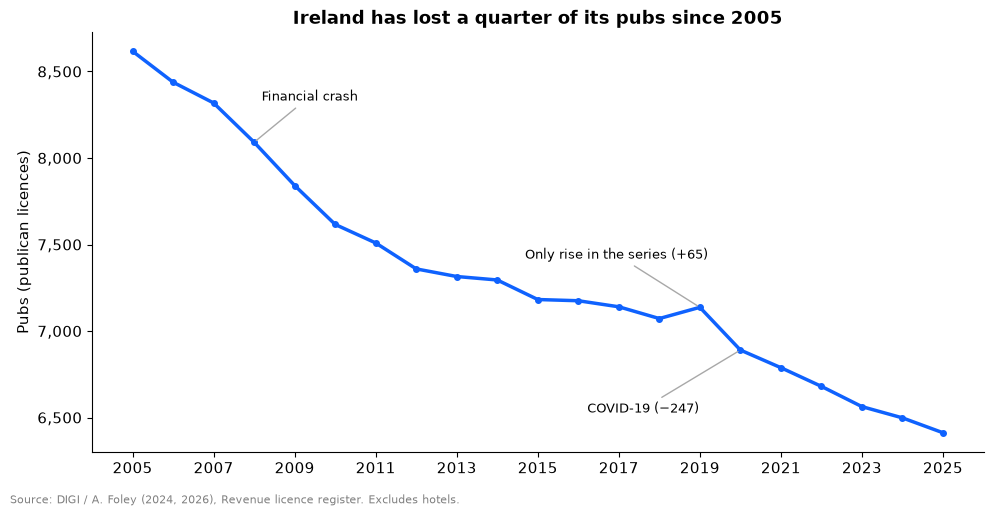

In [3]:
fig, ax = plt.subplots()
ax.plot(national.year, national.pub_licences, color=MAIN, linewidth=2.5, marker="o", markersize=4)

# (label, x offset, y offset) in points, placed so labels don't overlap
events = {
    2008: ("Financial crash", 40, 30),
    2019: ("Only rise in the series (+65)", -60, 35),
    2020: ("COVID-19 (−247)", -70, -45),
}
for year, (label, dx, dy) in events.items():
    y = national.loc[national.year == year, "pub_licences"].item()
    ax.annotate(label, xy=(year, y), xytext=(dx, dy), textcoords="offset points",
                ha="center", fontsize=9, arrowprops=dict(arrowstyle="-", color=MUTED))

ax.set_title("Ireland has lost a quarter of its pubs since 2005")
ax.set_ylabel("Pubs (publican licences)")
ax.set_xticks(range(2005, 2026, 2))
ax.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
fig.text(0.01, -0.02, "Source: DIGI / A. Foley (2024, 2026), Revenue licence register. Excludes hotels.", fontsize=8, color="grey")
fig.tight_layout()
fig.savefig(FIGURES / "01_national_trend.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. Closures by period
Was the decline fastest after the financial crash, or after the pandemic?

In [4]:
periods = [(2005, 2010), (2010, 2015), (2015, 2019), (2019, 2025)]
n = national.set_index("year")["pub_licences"]

rows = []
for start, end in periods:
    closed = n[start] - n[end]
    rows.append({
        "period": f"{start}–{end}",
        "pubs_closed": closed,
        "per_year": round(closed / (end - start), 1),
        "pct_lost": round(closed / n[start] * 100, 1),
    })
period_table = pd.DataFrame(rows)
period_table

,period,pubs_closed,per_year,pct_lost
0,2005–2010,1001,200.2,11.6
1,2010–2015,434,86.8,5.7
2,2015–2019,45,11.2,0.6
3,2019–2025,725,120.8,10.2


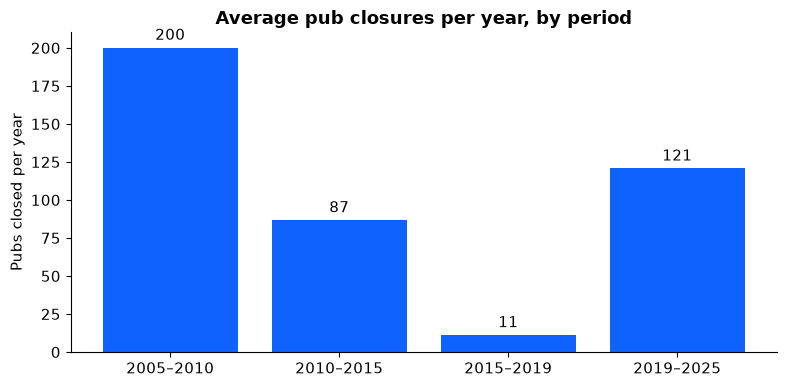

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(period_table.period, period_table.per_year, color=MAIN)
ax.bar_label(bars, fmt="%.0f", padding=3)
ax.set_title("Average pub closures per year, by period")
ax.set_ylabel("Pubs closed per year")
fig.tight_layout()
fig.savefig(FIGURES / "01_closures_by_period.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Which counties lost the most?
Ranked by **percentage** of pubs lost from 2005 to 2025, so small and large counties can be compared fairly.

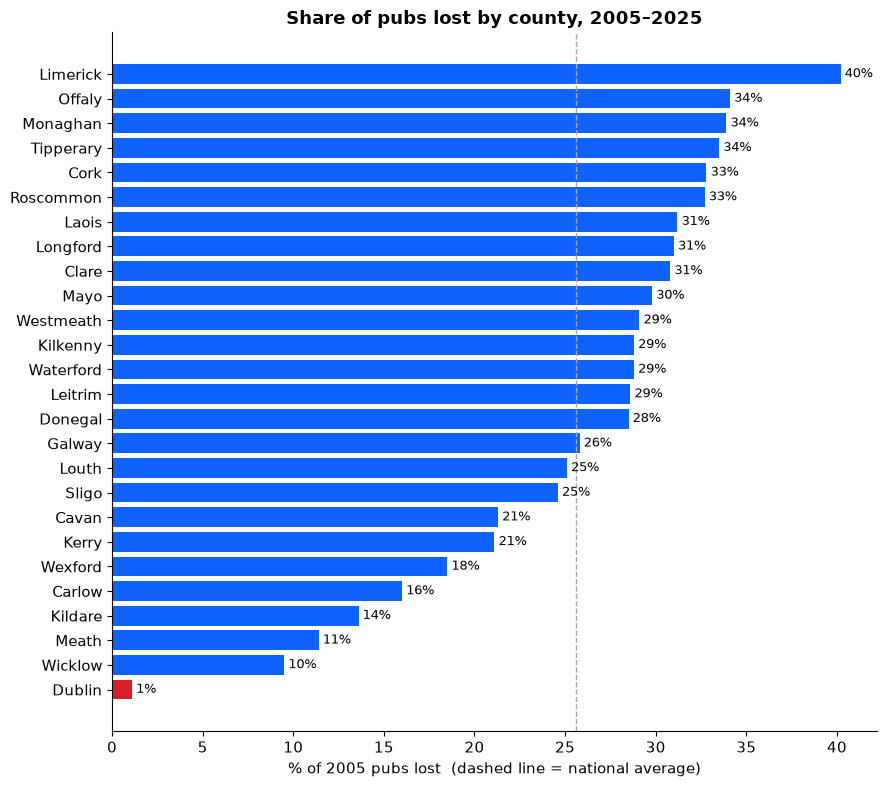

In [6]:
ranked = summary.sort_values("pct_lost")
colours = [HIGHLIGHT if c == "Dublin" else MAIN for c in ranked.county]

fig, ax = plt.subplots(figsize=(9, 8))
bars = ax.barh(ranked.county, ranked.pct_lost, color=colours)
ax.bar_label(bars, fmt="%.0f%%", padding=3, fontsize=9)
ax.axvline(summary.pubs_lost.sum() / summary.pubs_2005.sum() * 100,
           color=MUTED, linestyle="--", linewidth=1)
ax.set_title("Share of pubs lost by county, 2005–2025")
ax.set_xlabel("% of 2005 pubs lost  (dashed line = national average)")
fig.tight_layout()
fig.savefig(FIGURES / "01_county_ranking.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
print("Hardest hit:")
print(summary.head(5)[["county", "pubs_2005", "pubs_2025", "pubs_lost", "pct_lost"]].to_string(index=False))
print("\nLeast affected:")
print(summary.tail(5)[["county", "pubs_2005", "pubs_2025", "pubs_lost", "pct_lost"]].to_string(index=False))

Hardest hit:
   county  pubs_2005  pubs_2025  pubs_lost  pct_lost
 Limerick        478        286        192      40.2
   Offaly        164        108         56      34.1
 Monaghan        121         80         41      33.9
Tipperary        525        349        176      33.5
     Cork       1221        821        400      32.8

Least affected:
 county  pubs_2005  pubs_2025  pubs_lost  pct_lost
 Carlow        106         89         17      16.0
Kildare        191        165         26      13.6
  Meath        210        186         24      11.4
Wicklow        158        143         15       9.5
 Dublin        786        777          9       1.1


## 4. Dublin vs the rest of Ireland
Index each region to **2005 = 100** so their trends can be compared on one chart.
County data only exists for 2005 and 2019–2025, so the gap between those years is shown as a dashed line.

In [8]:
region = county.groupby(["region", "year"])["pubs"].sum().unstack("region")
region_index = (region / region.loc[2005] * 100).round(1)
region_index

region,Dublin,Outside Dublin
year,,
2005,100.0,100.0
2019,99.9,81.1
2020,95.9,78.5
2021,95.7,77.1
2022,96.6,75.8
2023,97.2,74.1
2024,98.3,73.1
2025,98.9,72.0


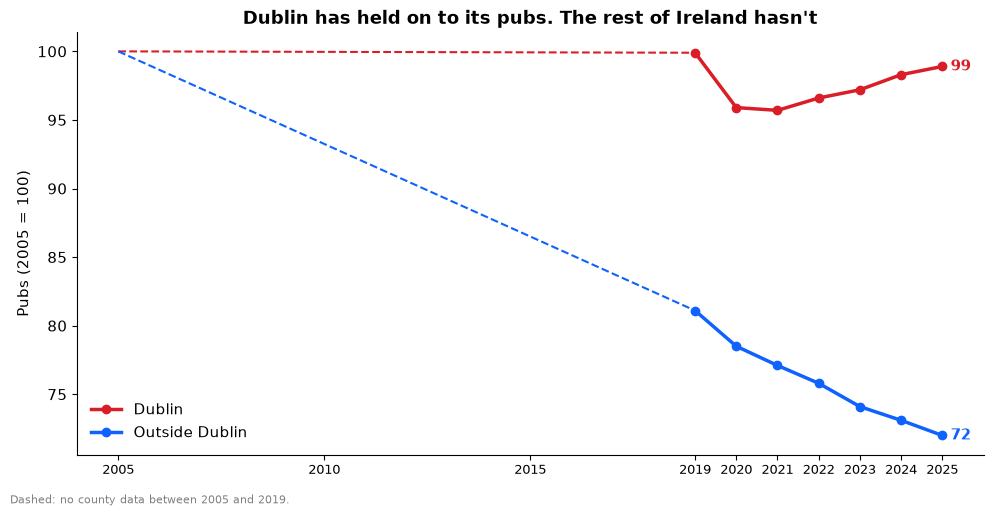

In [9]:
fig, ax = plt.subplots()
for name, colour in [("Dublin", HIGHLIGHT), ("Outside Dublin", MAIN)]:
    s = region_index[name]
    ax.plot(s.index[:2], s.values[:2], color=colour, linestyle="--", linewidth=1.5)   # 2005 -> 2019 gap
    ax.plot(s.index[1:], s.values[1:], color=colour, linewidth=2.5, marker="o", label=name)
    ax.annotate(f"{s.iloc[-1]:.0f}", xy=(s.index[-1], s.iloc[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", color=colour, fontweight="bold")

ax.set_title("Dublin has held on to its pubs. The rest of Ireland hasn't")
ax.set_ylabel("Pubs (2005 = 100)")
ax.set_xticks([2005, 2010, 2015, 2019, 2020, 2021, 2022, 2023, 2024, 2025])
ax.tick_params(axis="x", labelsize=9)
ax.legend(frameon=False)
fig.text(0.01, -0.02, "Dashed: no county data between 2005 and 2019.", fontsize=8, color="grey")
fig.tight_layout()
fig.savefig(FIGURES / "01_dublin_vs_rest.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Since the pandemic (2019 → 2025)
Which counties have lost the most pubs since COVID-19?

Note: 2020 and 2022 county figures don't sum exactly to the national total (source errors, documented in the data dictionary), so this section compares only **2019 and 2025**, which both balance.

In [10]:
wide = county.pivot(index="county", columns="year", values="pubs")
since_covid = pd.DataFrame({
    "pubs_2019": wide[2019],
    "pubs_2025": wide[2025],
})
since_covid["change"] = since_covid.pubs_2025 - since_covid.pubs_2019
since_covid["pct_change"] = (since_covid.change / since_covid.pubs_2019 * 100).round(1)
since_covid = since_covid.sort_values("pct_change")

print(f"National 2019 → 2025: {n[2025] - n[2019]:+,} pubs ({(n[2025] - n[2019]) / n[2019]:+.1%})")
since_covid.head(8)

National 2019 → 2025: -725 pubs (-10.2%)


,pubs_2019,pubs_2025,change,pct_change
county,,,,
Limerick,358,286,-72,-20.1
Monaghan,99,80,-19,-19.2
Kilkenny,195,161,-34,-17.4
Offaly,128,108,-20,-15.6
Waterford,216,185,-31,-14.4
Longford,91,78,-13,-14.3
Roscommon,198,171,-27,-13.6
Tipperary,401,349,-52,-13.0


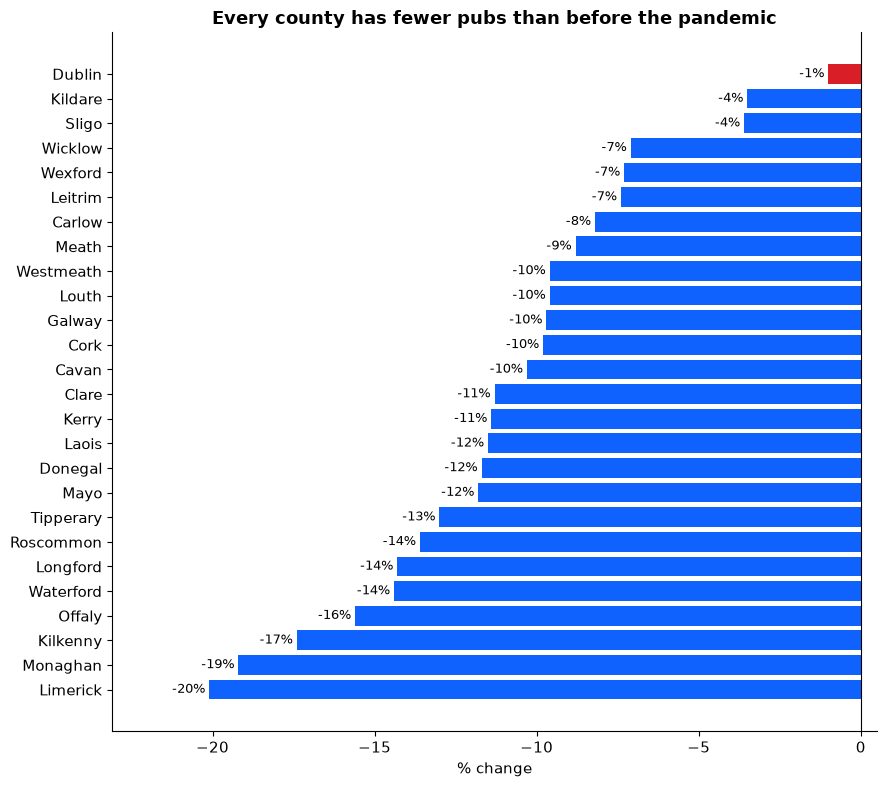

In [11]:
fig, ax = plt.subplots(figsize=(9, 8))
colours = [HIGHLIGHT if c == "Dublin" else MAIN for c in since_covid.index]
bars = ax.barh(since_covid.index, since_covid["pct_change"], color=colours)
ax.bar_label(bars, fmt="%+.0f%%", padding=3, fontsize=9)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlim(since_covid["pct_change"].min() - 3, 0.5)   # room for the labels
ax.set_title("Every county has fewer pubs than before the pandemic")
ax.set_xlabel("% change")
fig.tight_layout()
fig.savefig(FIGURES / "01_since_covid.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Findings
_Write these in your own words once you've looked at the charts above. Keep each to one sentence, and copy the strongest into the README's Key Findings table._

1. **National:** …
2. **Timing:** …
3. **Geography:** …
4. **Dublin:** …
5. **Since COVID:** …

**Caveats:** these are licence counts (venues, not visitors), cover all ages rather than young people specifically, and can't show *why* pubs closed. Rural depopulation, drink-driving laws, the smoking ban and drinking at home are all possible causes this data can't separate.